**1. Uso de Teachable Machine**

Para crear el modelo utilicé Teachable Machine, una herramienta web de Google que permite entrenar un modelo de clasificación de imágenes sin programar. Entré en https://teachablemachine.withgoogle.com/ y pulsé en “Empezar”.

Allí me dio a elegir entre varios tipos de proyecto. Elegí Proyecto de imagen y, dentro de él, la opción de modelo de imagen estándar, que es la que pide el enunciado.

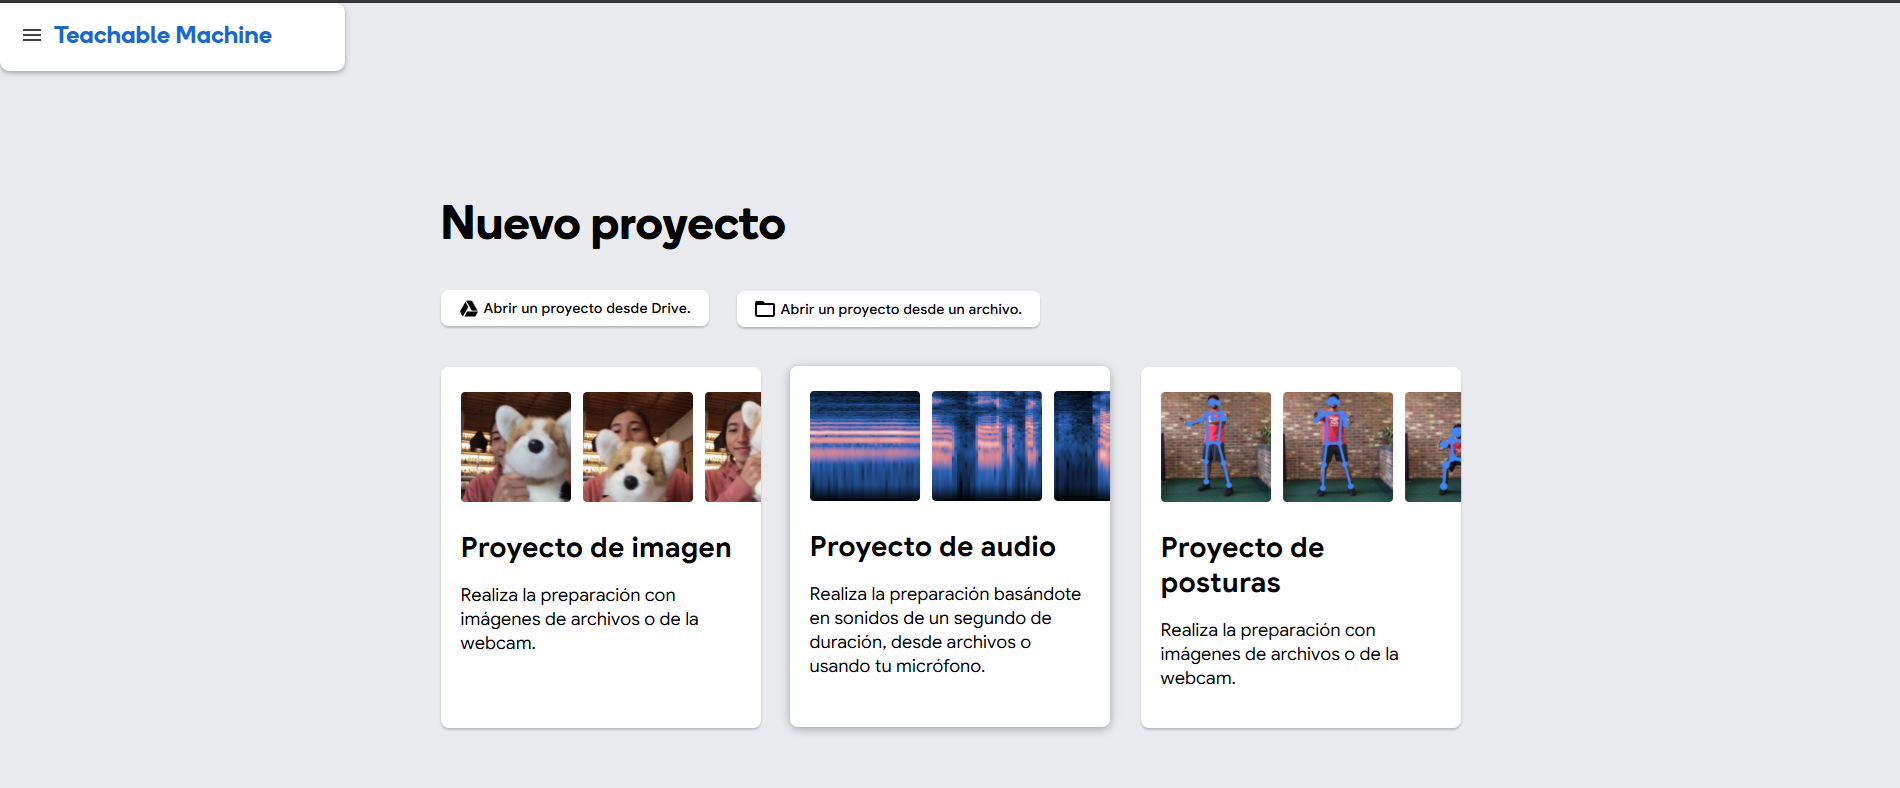

Al terminar de elegirlo me apareció el espacio de trabajo del proyecto, con dos clases por defecto (Class 1 y Class 2), una zona de preparación del modelo y una vista previa a la derecha. Ahí fue donde hice el resto del trabajo.

Para hacer el ejemplo elegí dos objetos que tenía a mano y que se distinguen bien entre sí: un móvil y una botella. Cada objeto sería una clase distinta, así que el modelo tendría que aprender a diferenciar uno del otro. Cambié el nombre de las clases para saber cuál era cuál: la primera para el móvil y la segunda para la botella.



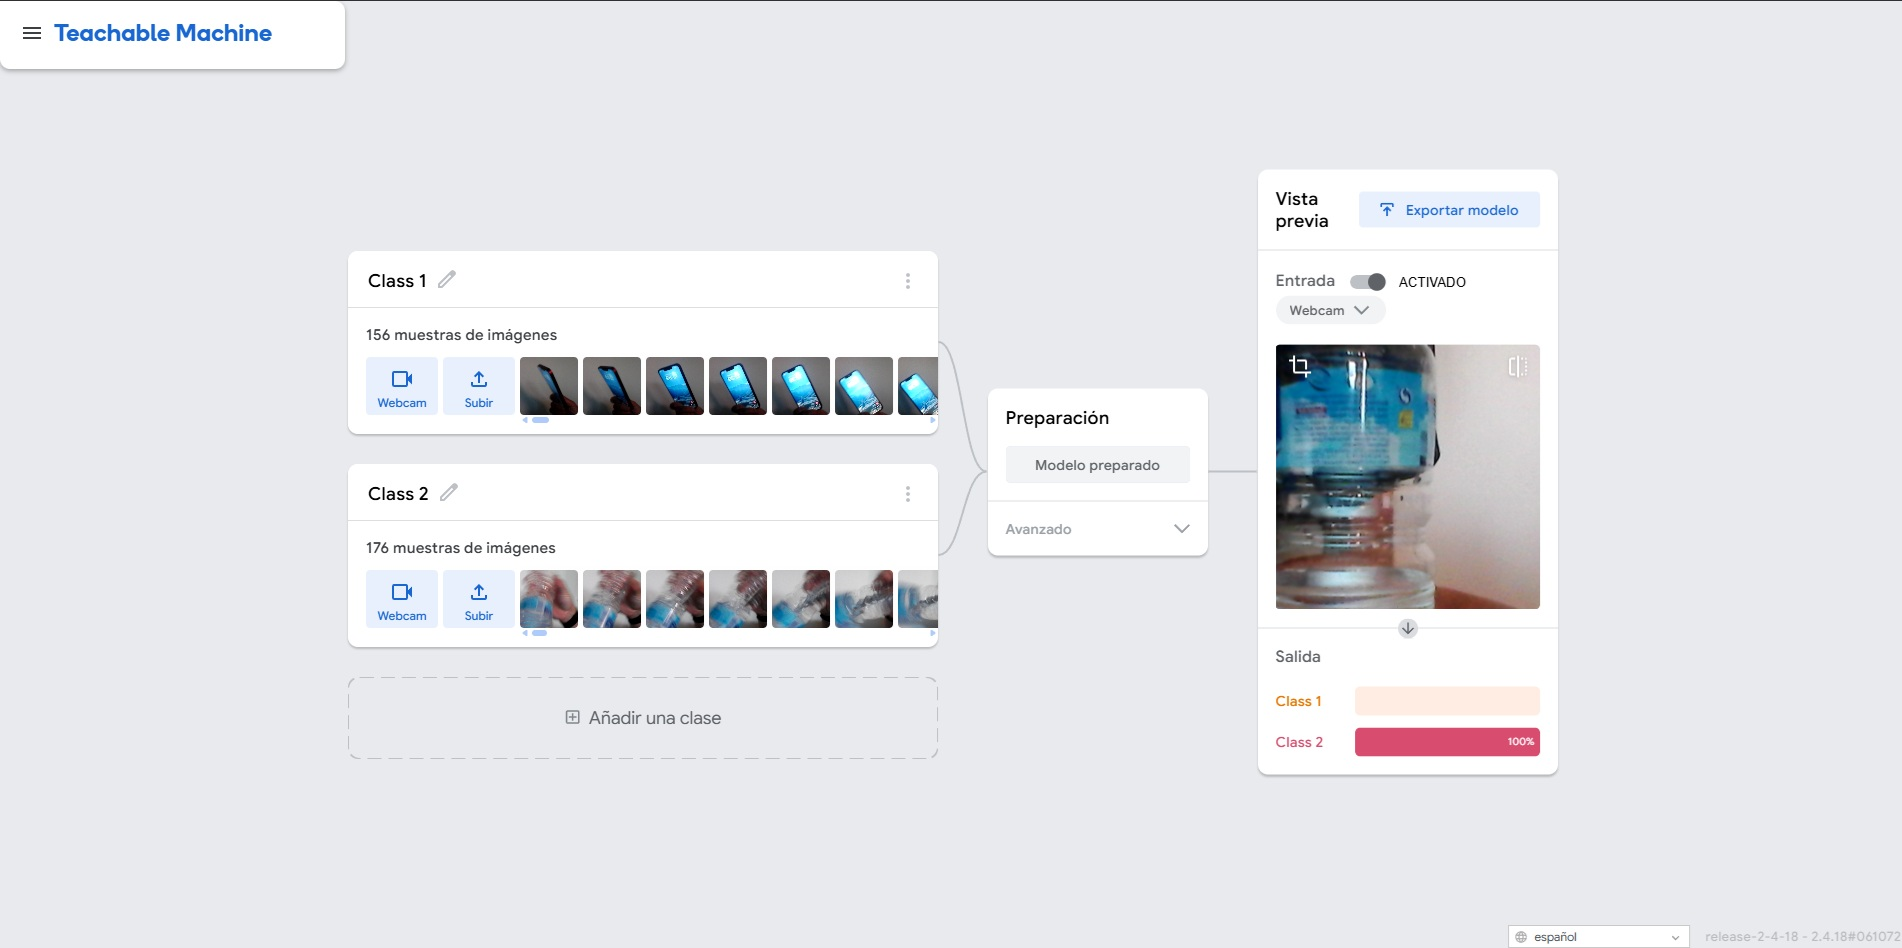

Exportar el modelo

Una vez preparado el modelo, lo exporté para poder usarlo fuera de Teachable Machine. Pulsé en el botón Exportar modelo de la vista previa y me salió una ventana con tres pestañas: Tensorflow.js, Tensorflow y Tensorflow Lite.

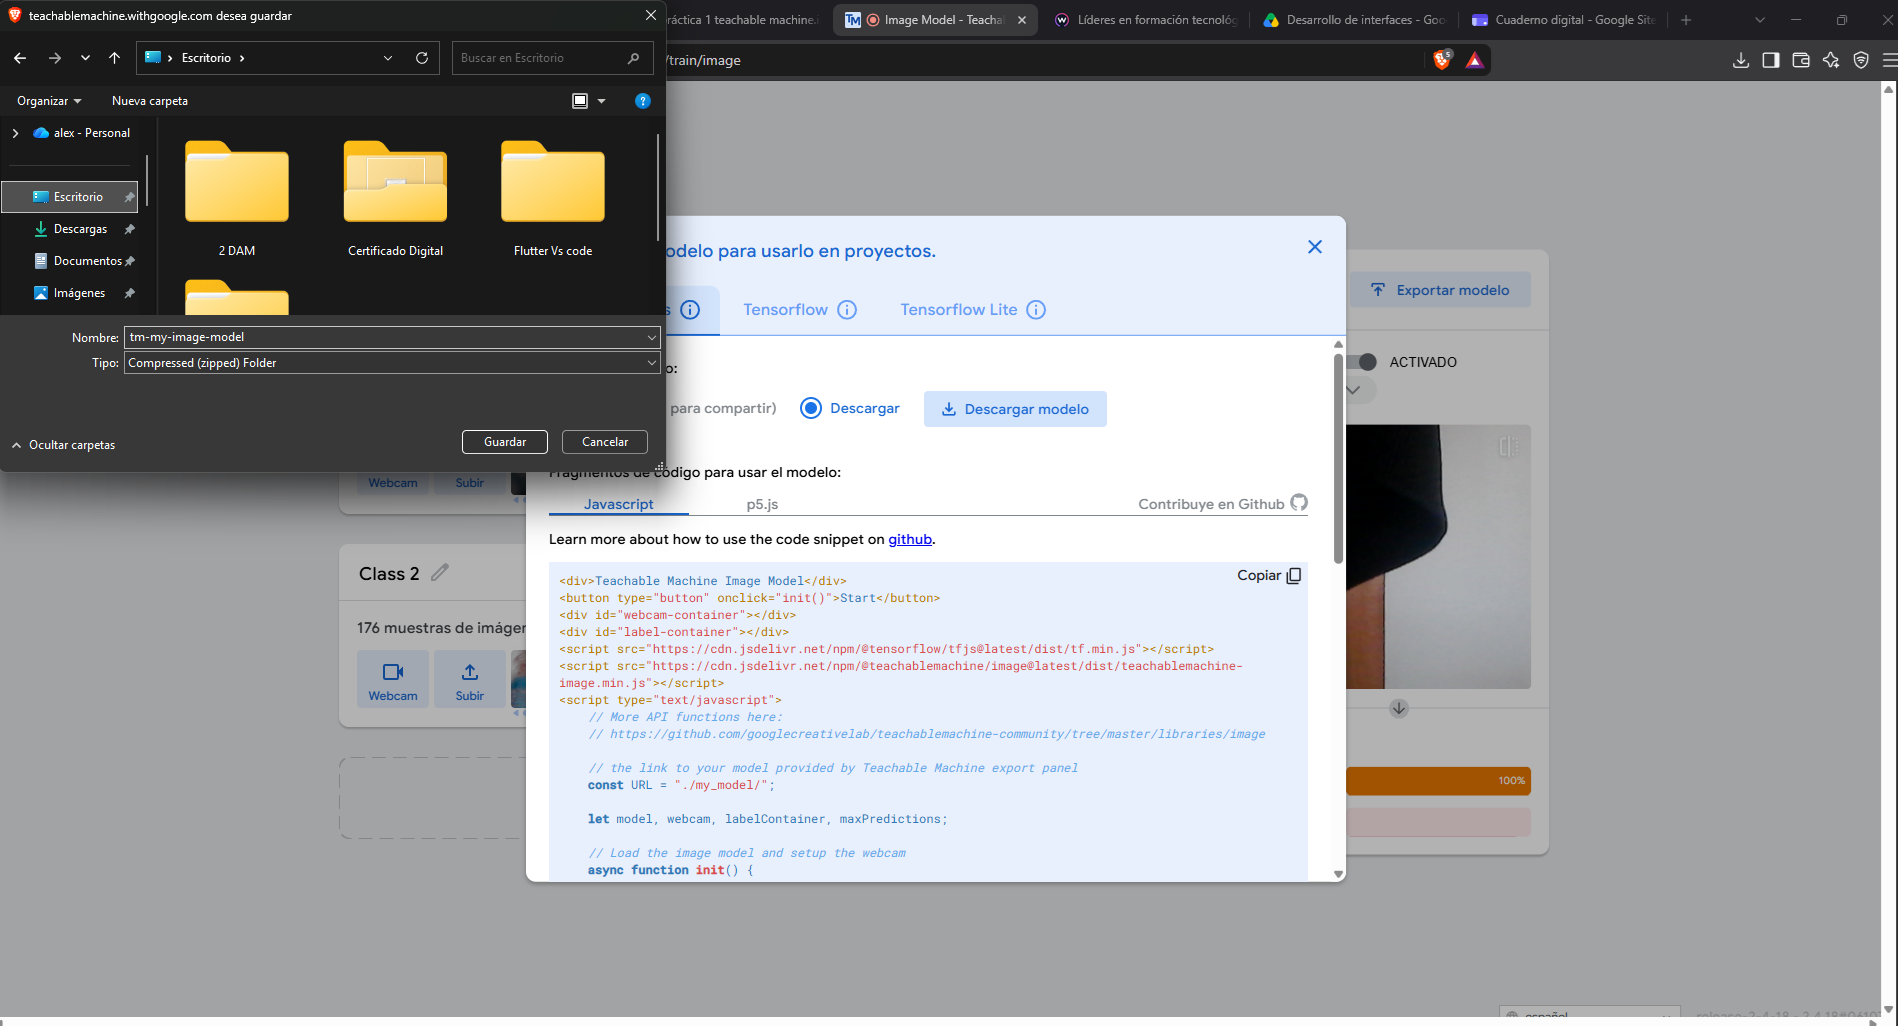

El enunciado pedía descargar el modelo en dos formatos, así que hice la descarga dos veces:

Tensorflow.js: en esta pestaña elegí la opción Descargar y pulsé en “Descargar modelo”. El navegador me abrió una ventana para elegir dónde guardarlo y lo guardé en el escritorio. Se descargó un archivo comprimido llamado tm-my-image-model.zip, que contiene model.json, metadata.json y weights.bin. Este es el que uso para probar el modelo en local con JavaScript.

Tensorflow: en la pestaña de Tensorflow elegí el formato Keras y pulsé en “Descargar mi modelo”. Se descargó el archivo converted_keras.zip, que contiene keras_model.h5 y labels.txt. Este no lo uso ahora, pero lo guardé porque el enunciado dice que lo necesitaré en una práctica posterior.

 **2 .Estructura de carpetas y código de la aplicación**

Para probar el modelo en local creé una carpeta llamada clasificador con la estructura que pedía el enunciado. Dentro hice una carpeta modelo, donde copié los tres archivos del modelo descargado en Tensorflow.js (model.json, metadata.json y weights.bin), y creé tres archivos más: index.html, styles.css y app.js. Trabajé con ellos en Visual Studio Code.

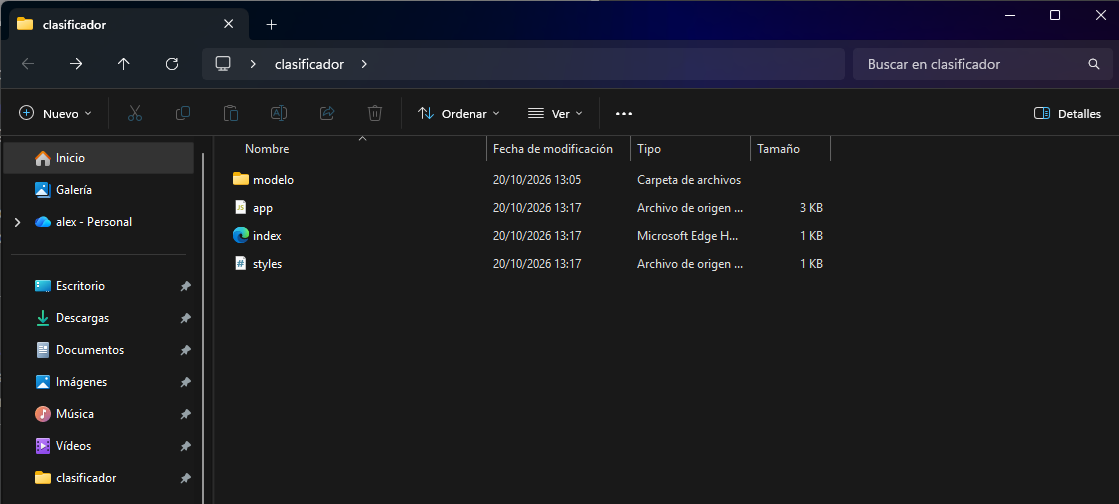

Index.html

In [ ]:
<!DOCTYPE html>
<html lang="es">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Clasificador de imágenes</title>
    <link rel="stylesheet" href="styles.css">
</head>
<body>
    <h1>Clasificador de imágenes</h1>

    <main>
        <section class="tarjeta">
            <h2>Clasificador</h2>

            <div id="botones">
                <button id="btnIniciar" disabled>Iniciar</button>
                <button id="btnParar" disabled>Parar</button>
            </div>

            <div id="subida">
                <label for="inputImagen">O sube una imagen para clasificarla:</label>
                <input type="file" id="inputImagen" accept="image/*" disabled>
            </div>

            <div id="umbral">
                <label for="rangoUmbral">
                    Valor mínimo de coincidencia: <span id="valorUmbral">90</span>%
                </label>
                <input type="range" id="rangoUmbral" min="50" max="100" value="90">
            </div>

            <div id="contenedor-webcam"></div>
            <img id="imagenSubida" alt="Imagen subida" hidden>

            <p id="mensaje"></p>
            <div id="resultado"></div>
        </section>

        <section class="tarjeta">
            <h2>Histórico</h2>
            <button id="btnBorrar">Borrar histórico</button>
            <ul id="historico"></ul>
        </section>
    </main>

    <script src="https://cdn.jsdelivr.net/npm/@tensorflow/tfjs@1.3.1/dist/tf.min.js"></script>
    <script src="https://cdn.jsdelivr.net/npm/@teachablemachine/image@0.8/dist/teachablemachine-image.min.js"></script>
    <script src="app.js"></script>
</body>
</html>


Style.css

In [ ]:
* {
    box-sizing: border-box;
}

body {
    font-family: Arial, sans-serif;
    background-color: #f2f4f8;
    color: #222;
    margin: 0;
    padding: 20px;
}

h1 {
    text-align: center;
    margin-bottom: 20px;
}

main {
    max-width: 600px;
    margin: 0 auto;
}

.tarjeta {
    background-color: white;
    border-radius: 10px;
    padding: 20px;
    margin-bottom: 20px;
    text-align: center;
    box-shadow: 0 2px 6px rgba(0, 0, 0, 0.15);
}

h2 {
    margin-top: 0;
}

button {
    font-size: 16px;
    padding: 8px 20px;
    margin: 5px;
    border: none;
    border-radius: 5px;
    background-color: #3366cc;
    color: white;
    cursor: pointer;
}

button:hover:enabled {
    background-color: #254a99;
}

button:disabled {
    background-color: #b5bcc9;
    cursor: not-allowed;
}

#subida,
#umbral {
    margin: 15px 0;
}

#subida label,
#umbral label {
    display: block;
    margin-bottom: 5px;
}

#rangoUmbral {
    width: 80%;
}

#contenedor-webcam {
    display: flex;
    justify-content: center;
}

canvas,
#imagenSubida {
    max-width: 100%;
    height: auto;
    border-radius: 8px;
}

#imagenSubida {
    max-height: 300px;
}

#mensaje {
    font-size: 22px;
    font-weight: bold;
    margin: 15px 0 10px 0;
}

.coincidencia {
    color: #1a8a3a;
}

.sin-coincidencia {
    color: #c0392b;
}

#resultado div {
    margin: 5px;
    font-size: 18px;
}

#historico {
    list-style: none;
    padding: 0;
    margin: 15px 0 0 0;
    text-align: left;
}

#historico li {
    padding: 6px 0;
    border-bottom: 1px solid #e0e0e0;
}

/* pantallas pequeñas (móvil) */
@media (max-width: 480px) {
    body {
        padding: 10px;
    }

    button {
        width: 100%;
        margin: 5px 0;
    }

    #rangoUmbral {
        width: 100%;
    }
}


App.js

In [ ]:
// rutas del modelo exportado de Teachable Machine
const rutaModelo = "modelo/model.json";
const rutaMetadatos = "modelo/metadata.json";

// mensaje que se muestra según la clase ganadora
const mensajes = {
    "Class 1": "Veo un móvil",
    "Class 2": "Veo una botella"
};
const mensajeSinCoincidencia = "No reconozco ningún objeto";

let modelo;
let webcam;
let totalClases;
let funcionando = false;
let idAnimacion;
let ultimoTexto = "";

// elementos de la página
const btnIniciar = document.getElementById("btnIniciar");
const btnParar = document.getElementById("btnParar");
const btnBorrar = document.getElementById("btnBorrar");
const inputImagen = document.getElementById("inputImagen");
const rangoUmbral = document.getElementById("rangoUmbral");
const valorUmbral = document.getElementById("valorUmbral");
const contenedorWebcam = document.getElementById("contenedor-webcam");
const imagenSubida = document.getElementById("imagenSubida");
const parrafoMensaje = document.getElementById("mensaje");
const contenedorResultado = document.getElementById("resultado");
const historico = document.getElementById("historico");

// el modelo se carga una sola vez al abrir la página
async function cargarModelo() {
    parrafoMensaje.innerHTML = "Cargando modelo...";

    try {
        modelo = await tmImage.load(rutaModelo, rutaMetadatos);
    } catch (error) {
        parrafoMensaje.innerHTML = "Error al cargar el modelo";
        console.log(error);
        return;
    }

    totalClases = modelo.getTotalClasses();

    // un div por cada clase para mostrar el resultado
    for (let i = 0; i < totalClases; i++) {
        contenedorResultado.appendChild(document.createElement("div"));
    }

    parrafoMensaje.innerHTML = "";
    btnIniciar.disabled = false;
    inputImagen.disabled = false;
}

async function iniciar() {
    if (funcionando) {
        return;
    }

    btnIniciar.disabled = true;
    imagenSubida.hidden = true;
    limpiarResultado();
    ultimoTexto = "";

    try {
        // la webcam se crea de nuevo cada vez que se inicia
        webcam = new tmImage.Webcam(300, 300, true);
        await webcam.setup();
        await webcam.play();
    } catch (error) {
        parrafoMensaje.innerHTML = "No se ha podido encender la cámara";
        btnIniciar.disabled = false;
        return;
    }

    contenedorWebcam.appendChild(webcam.canvas);
    funcionando = true;
    btnParar.disabled = false;
    idAnimacion = window.requestAnimationFrame(bucle);
}

function parar() {
    if (!funcionando) {
        return;
    }

    funcionando = false;
    window.cancelAnimationFrame(idAnimacion);

    // apagar la cámara y limpiar la pantalla
    webcam.stop();
    contenedorWebcam.innerHTML = "";
    limpiarResultado();

    btnParar.disabled = true;
    btnIniciar.disabled = false;
}

async function bucle() {
    if (!funcionando) {
        return;
    }

    webcam.update();
    const prediccion = await modelo.predict(webcam.canvas);

    // por si se ha pulsado parar mientras predecía
    if (!funcionando) {
        return;
    }

    const texto = mostrarResultado(prediccion);

    // en el histórico solo se apunta cuando cambia el resultado
    if (texto !== ultimoTexto) {
        anotarHistorico(texto);
        ultimoTexto = texto;
    }

    idAnimacion = window.requestAnimationFrame(bucle);
}

// escribe los porcentajes y el mensaje, y devuelve el texto del mensaje
function mostrarResultado(prediccion) {
    const umbral = Number(rangoUmbral.value) / 100;
    let ganadora = prediccion[0];

    for (let i = 0; i < totalClases; i++) {
        const porcentaje = (prediccion[i].probability * 100).toFixed(0);
        contenedorResultado.childNodes[i].innerHTML = prediccion[i].className + ": " + porcentaje + "%";

        if (prediccion[i].probability > ganadora.probability) {
            ganadora = prediccion[i];
        }
    }

    let texto;
    if (ganadora.probability >= umbral) {
        texto = mensajes[ganadora.className] || "Veo " + ganadora.className;
        parrafoMensaje.className = "coincidencia";
    } else {
        texto = mensajeSinCoincidencia;
        parrafoMensaje.className = "sin-coincidencia";
    }

    parrafoMensaje.innerHTML = texto;
    return texto;
}

function limpiarResultado() {
    for (let i = 0; i < contenedorResultado.childNodes.length; i++) {
        contenedorResultado.childNodes[i].innerHTML = "";
    }
    parrafoMensaje.innerHTML = "";
    parrafoMensaje.className = "";
}

function anotarHistorico(texto) {
    const hora = new Date().toLocaleTimeString();
    const elemento = document.createElement("li");
    elemento.innerHTML = hora + " - " + texto;

    // lo más reciente arriba
    historico.prepend(elemento);

    // máximo 20 apuntes
    while (historico.children.length > 20) {
        historico.removeChild(historico.lastChild);
    }
}

function subirImagen() {
    const archivo = inputImagen.files[0];
    if (!archivo) {
        return;
    }

    // si la cámara estaba encendida, se apaga
    parar();

    imagenSubida.onload = async function () {
        const prediccion = await modelo.predict(imagenSubida);
        const texto = mostrarResultado(prediccion);
        anotarHistorico("Imagen subida (" + archivo.name + "): " + texto);
    };

    imagenSubida.src = URL.createObjectURL(archivo);
    imagenSubida.hidden = false;

    // para poder volver a subir el mismo archivo
    inputImagen.value = "";
}

btnIniciar.addEventListener("click", iniciar);
btnParar.addEventListener("click", parar);
btnBorrar.addEventListener("click", function () {
    historico.innerHTML = "";
});
inputImagen.addEventListener("change", subirImagen);
rangoUmbral.addEventListener("input", function () {
    valorUmbral.innerHTML = rangoUmbral.value;
});

cargarModelo();


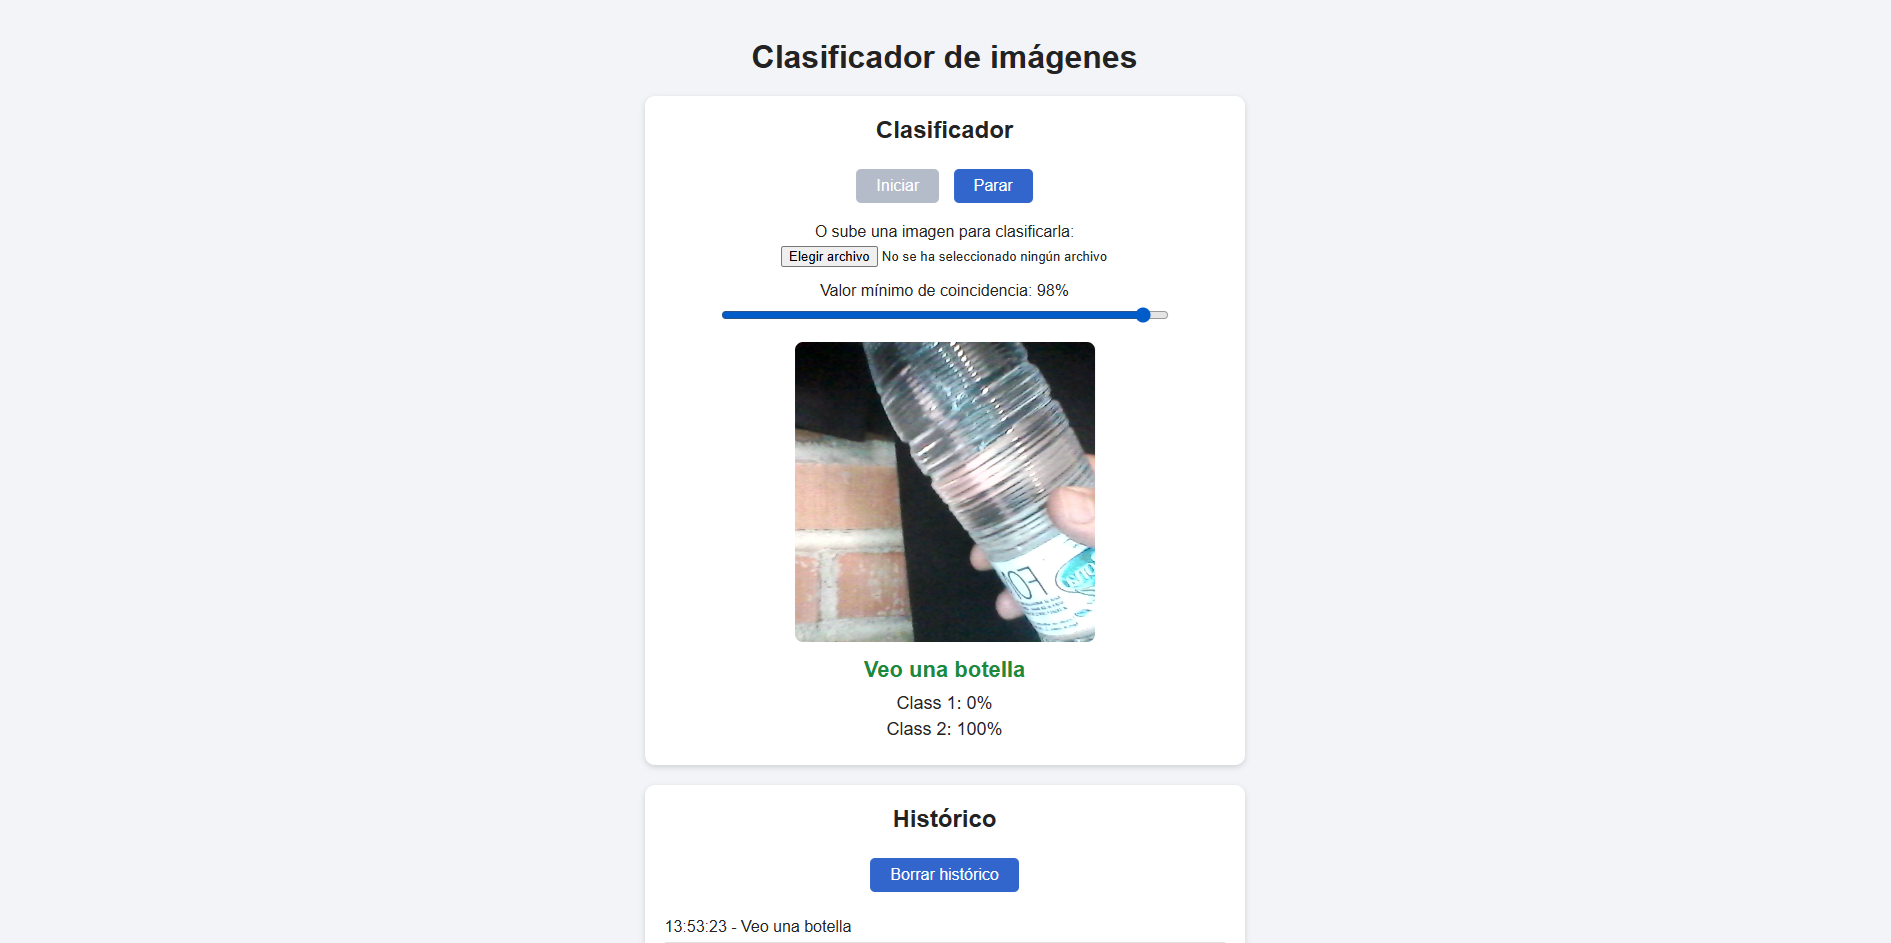